# Analytic question (Regression 2.1): Can we predict the goal difference between two teams in a 2026 World Cup match using only information that is available before the match?
# Response variable: Goal_Diff = home team goals − away team goals (104 matches)

# Importing libraries

In [1]:
import pandas as pd
import numpy as np
import math
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

# folder for saving the figures used in the report
os.makedirs("figures", exist_ok=True)

# Loading the data

We are using four datasets:
* Match by match results of the 2026 World Cup (same as Assessment 2). Dataset: https://fbref.com/en/comps/1/schedule/World-Cup-Scores-and-Fixtures
* FIFA ranking released on 10 June 2026, the last ranking before the World Cup. Dataset: https://www.mlssoccer.com/news/fifa-world-rankings-every-team-at-the-world-cup
* International results from 20 December 2022 to 10 June 2026, used for each team's form before the World Cup. Dataset: https://github.com/martj42/international_results
* World Cup finals matches from 1930 to 2022, used to count each team's previous World Cups. Dataset: https://github.com/martj42/international_results

In [2]:
# Reading the world cup 2026 matches csv
df_matches = pd.read_csv("worldcup_matches_data.csv")

# Reading the FIFA ranking (10 June 2026)
df_rank = pd.read_csv("fifa_ranking_june2026.csv")

# Reading the international results from 2022 to 2026
df_results = pd.read_csv("international_results_2022_2026.csv")

# Reading the World Cup finals matches from 1930 to 2022
df_wc_history = pd.read_csv("world_cup_history.csv")

print("World Cup 2026 matches: %d rows" % df_matches.shape[0])
print("FIFA ranking: %d teams" % df_rank.shape[0])
print("International results 2022-2026: %d matches" % df_results.shape[0])
print("World Cup history 1930-2022: %d matches" % df_wc_history.shape[0])

World Cup 2026 matches: 107 rows
FIFA ranking: 48 teams
International results 2022-2026: 3648 matches
World Cup history 1930-2022: 964 matches


# Data wrangling

Same as Assessment 2, the csv has blank rows that we don't need and the Score column is a text value like 2–1, so we split it into home goals and away goals. Penalty shootout scores in brackets are removed because they are not goals scored during the match.
The team names also have country codes attached (e.g. "Mexico mx" and "za South Africa") and some teams are named differently in the other datasets (e.g. "Korea Republic" and "South Korea"), so we clean the names.

In [3]:
# dropping the empty rows
df_matches = df_matches.dropna(subset=["Score"])
df_matches = df_matches[df_matches["Score"].str.strip() != ""]
df_matches = df_matches.reset_index(drop=True)

# removing the penalty shootout scores
df_matches["Score_clean"] = df_matches["Score"].str.replace(r"\(.*?\)", "", regex=True)
df_matches["Score_clean"] = df_matches["Score_clean"].str.strip()

# splitting the goals into Home_Goals and Away_Goals
df_matches[["Home_Goals", "Away_Goals"]] = df_matches["Score_clean"].str.split("–", expand=True)

# converting the goal columns from text to whole numbers
df_matches["Home_Goals"] = df_matches["Home_Goals"].astype(int)
df_matches["Away_Goals"] = df_matches["Away_Goals"].astype(int)

# removing the country codes (end of the home team name, start of the away team name)
df_matches["Home"] = df_matches["Home"].str.rsplit(" ", n=1).str[0]
df_matches["Away"] = df_matches["Away"].str.split(" ", n=1).str[1]

# renaming the teams so the names are the same in all datasets
name_changes = {
    "Korea Republic": "South Korea",
    "Czechia": "Czech Republic",
    "Bosnia–Herz": "Bosnia and Herzegovina",
    "USA": "United States",
    "Côte d'Ivoire": "Ivory Coast",
    "Cabo Verde": "Cape Verde",
    "Congo DR": "DR Congo",
    "IR Iran": "Iran",
    "Türkiye": "Turkey"
}
df_matches["Home"] = df_matches["Home"].replace(name_changes)
df_matches["Away"] = df_matches["Away"].replace(name_changes)

# converting the date column to a date
df_matches["Date"] = pd.to_datetime(df_matches["Date"], format="%m/%d/%Y")

# giving each match an ID number
df_matches["Match_ID"] = range(1, len(df_matches) + 1)

print("Matches remaining after cleaning: %d" % df_matches.shape[0])

# checking that every team can be found in the ranking file
all_teams = set(df_matches["Home"]) | set(df_matches["Away"])
print("Teams not found in the ranking file:", all_teams - set(df_rank["Team"]))

# Displaying the top 10 rows
df_matches[["Match_ID", "Round", "Home", "Home_Goals", "Away_Goals", "Away"]].head(10)

Matches remaining after cleaning: 104
Teams not found in the ranking file: set()


,Match_ID,Round,Home,Home_Goals,Away_Goals,Away
0,1,Group stage,Mexico,2,0,South Africa
1,2,Group stage,South Korea,2,1,Czech Republic
2,3,Group stage,Canada,1,1,Bosnia and Herzegovina
3,4,Group stage,United States,4,1,Paraguay
4,5,Group stage,Qatar,1,1,Switzerland
5,6,Group stage,Brazil,1,1,Morocco
6,7,Group stage,Australia,2,0,Turkey
7,8,Group stage,Haiti,0,1,Scotland
8,9,Group stage,Germany,7,1,Curaçao
9,10,Group stage,Netherlands,2,2,Japan


# Team information before the World Cup

For each team we are calculating the win rate, average goals scored and average goals conceded per match in the last World Cup cycle (19 December 2022 to 10 June 2026), and the number of previous World Cups.

In [4]:
# converting the date column to a date
df_results["date"] = pd.to_datetime(df_results["date"])

# keeping only the matches between the 2022 World Cup final and the 2026 World Cup
df_cycle = df_results[(df_results["date"] > "2022-12-18") & (df_results["date"] < "2026-06-11")]
print("Matches in the 2022-2026 cycle: %d" % df_cycle.shape[0])

# putting the home side and the away side of each match underneath each other
home_side = df_cycle[["home_team", "home_score", "away_score"]].rename(
    columns={"home_team": "Team", "home_score": "Goals_For", "away_score": "Goals_Against"})
away_side = df_cycle[["away_team", "away_score", "home_score"]].rename(
    columns={"away_team": "Team", "away_score": "Goals_For", "home_score": "Goals_Against"})
df_team_games = pd.concat([home_side, away_side], ignore_index=True)

# 1 if the team won the match, 0 if it was a draw or a loss
df_team_games["Win"] = np.where(df_team_games["Goals_For"] > df_team_games["Goals_Against"], 1, 0)

# calculating the win rate and average goals for each team
df_form = df_team_games.groupby("Team").agg(
    Pre_Matches=("Win", "count"),
    Pre_WinRate=("Win", "mean"),
    Pre_GoalsFor=("Goals_For", "mean"),
    Pre_GoalsAgainst=("Goals_Against", "mean")
).reset_index()

# counting the number of previous World Cups for each team
df_wc_history["Year"] = pd.to_datetime(df_wc_history["date"]).dt.year
wc_home = df_wc_history[["home_team", "Year"]].rename(columns={"home_team": "Team"})
wc_away = df_wc_history[["away_team", "Year"]].rename(columns={"away_team": "Team"})
df_wc_teams = pd.concat([wc_home, wc_away]).drop_duplicates()
df_apps = df_wc_teams.groupby("Team").size().reset_index(name="WC_Apps")

Matches in the 2022-2026 cycle: 3648


In [5]:
# joining the team information into one table
df_teams = pd.merge(df_rank, df_form, on="Team", how="left")
df_teams = pd.merge(df_teams, df_apps, on="Team", how="left")

print("Missing values:")
print(df_teams.isnull().sum())

# Cape Verde, Curaçao, Jordan and Uzbekistan are playing their first World Cup, so their WC_Apps is 0
print("\nTeams with no previous World Cup:", list(df_teams[df_teams["WC_Apps"].isnull()]["Team"]))
df_teams["WC_Apps"] = df_teams["WC_Apps"].fillna(0).astype(int)

# 1 for the three host nations, 0 for everyone else
hosts = ["United States", "Mexico", "Canada"]
df_teams["Host"] = np.where(df_teams["Team"].isin(hosts), 1, 0)

# Displaying the team table
df_teams.sort_values("FIFA_Rank").round(2)

Missing values:
Team                0
FIFA_Rank           0
Pre_Matches         0
Pre_WinRate         0
Pre_GoalsFor        0
Pre_GoalsAgainst    0
WC_Apps             4
dtype: int64

Teams with no previous World Cup: ['Uzbekistan', 'Jordan', 'Cape Verde', 'Curaçao']


,Team,FIFA_Rank,Pre_Matches,Pre_WinRate,Pre_GoalsFor,Pre_GoalsAgainst,WC_Apps,Host
0,Argentina,1,39,0.82,2.18,0.36,18,0
1,Spain,2,41,0.73,2.63,0.83,16,0
2,France,3,40,0.65,2.22,0.88,16,0
3,England,4,41,0.68,2.10,0.56,16,0
4,Portugal,5,40,0.70,2.55,0.82,8,0
5,Brazil,6,37,0.46,1.78,1.14,22,0
6,Morocco,7,51,0.76,2.16,0.37,6,0
7,Netherlands,8,40,0.55,2.35,1.08,11,0
8,Belgium,9,38,0.55,2.29,0.84,14,0
9,Germany,10,40,0.57,2.15,1.20,20,0


# Team form during the tournament

We are turning the 104 matches into 208 rows (one row for each team in each match). For each row we only use the team's earlier matches in the tournament, so nothing from the match itself is used.

In [6]:
# one row for the home team and one row for the away team of each match
home_rows = df_matches[["Match_ID", "Date", "Home", "Away", "Home_Goals", "Away_Goals"]].rename(
    columns={"Home": "Team", "Away": "Opponent", "Home_Goals": "Goals", "Away_Goals": "Conceded"})
home_rows["Side"] = "Home"
away_rows = df_matches[["Match_ID", "Date", "Away", "Home", "Away_Goals", "Home_Goals"]].rename(
    columns={"Away": "Team", "Home": "Opponent", "Away_Goals": "Goals", "Home_Goals": "Conceded"})
away_rows["Side"] = "Away"
df_long = pd.concat([home_rows, away_rows], ignore_index=True)

# sorting each team's matches by date
df_long = df_long.sort_values(["Team", "Date"]).reset_index(drop=True)

# number of matches the team played before this one
df_long["Prev_Matches"] = df_long.groupby("Team").cumcount()

# goals before this match (running total minus the current match)
df_long["Prev_Goals"] = df_long.groupby("Team")["Goals"].cumsum() - df_long["Goals"]
df_long["Prev_Conceded"] = df_long.groupby("Team")["Conceded"].cumsum() - df_long["Conceded"]

# average goal difference per match before this match
df_long["Tourn_GD"] = (df_long["Prev_Goals"] - df_long["Prev_Conceded"]) / df_long["Prev_Matches"]

# days of rest since the previous match
df_long["Rest_Days"] = df_long.groupby("Team")["Date"].diff().dt.days

print("Rows: %d" % df_long.shape[0])

# Displaying Argentina's matches as an example
df_long[df_long["Team"] == "Argentina"][["Match_ID", "Date", "Opponent", "Goals", "Conceded", "Prev_Matches", "Tourn_GD", "Rest_Days"]]

Rows: 208


,Match_ID,Date,Opponent,Goals,Conceded,Prev_Matches,Tourn_GD,Rest_Days
4,19,2026-06-16,Algeria,3,0,0,NaN,NaN
5,41,2026-06-22,Austria,2,0,1,3.000000,6.0
6,71,2026-06-27,Jordan,3,1,2,2.500000,5.0
7,87,2026-07-03,Cape Verde,3,2,3,2.333333,6.0
8,95,2026-07-07,Egypt,3,2,4,2.000000,4.0
9,100,2026-07-11,Switzerland,3,1,5,1.800000,4.0
10,102,2026-07-15,England,2,1,6,1.833333,4.0
11,104,2026-07-19,Spain,0,1,7,1.714286,4.0


# Handling missing values

A team's first match has no earlier matches in the tournament, so Tourn_GD and Rest_Days are missing. Tourn_GD is replaced with 0 (no tournament form yet), and the difference in rest days is set to 0 because in the first round both teams are playing their first match.

In [7]:
print("Missing values:")
print(df_long[["Tourn_GD", "Rest_Days"]].isnull().sum())

# adding the team information to each row
df_long = pd.merge(df_long, df_teams, on="Team", how="left")

# replacing the missing values with 0
df_long["Tourn_GD"] = df_long["Tourn_GD"].fillna(0)

Missing values:
Tourn_GD     48
Rest_Days    48
dtype: int64


# Data preparation

We are predicting the difference between two teams, so every explanatory variable is the home team value minus the away team value:
* Rank_Diff – FIFA ranking
* WinRate_Diff – win rate before the World Cup
* GoalsFor_Diff – goals scored per match before the World Cup
* GoalsAgainst_Diff – goals conceded per match before the World Cup
* WC_Apps_Diff – number of previous World Cups
* Host_Diff – host nation
* Tourn_GD_Diff – goal difference per match in earlier 2026 World Cup matches
* Rest_Days_Diff – days of rest since the previous match

In [8]:
# splitting the rows into home teams and away teams
cols = ["Match_ID", "Team", "FIFA_Rank", "Pre_WinRate", "Pre_GoalsFor", "Pre_GoalsAgainst",
        "WC_Apps", "Host", "Tourn_GD", "Rest_Days"]
df_home = df_long[df_long["Side"] == "Home"][cols]
df_away = df_long[df_long["Side"] == "Away"][cols]

# joining them back together, one row per match
df_21 = pd.merge(df_home, df_away, on="Match_ID", suffixes=("_H", "_A"))
df_21 = pd.merge(df_matches[["Match_ID", "Home_Goals", "Away_Goals"]], df_21, on="Match_ID")

# calculating the 8 explanatory variables (home minus away)
df_21["Rank_Diff"] = df_21["FIFA_Rank_H"] - df_21["FIFA_Rank_A"]
df_21["WinRate_Diff"] = df_21["Pre_WinRate_H"] - df_21["Pre_WinRate_A"]
df_21["GoalsFor_Diff"] = df_21["Pre_GoalsFor_H"] - df_21["Pre_GoalsFor_A"]
df_21["GoalsAgainst_Diff"] = df_21["Pre_GoalsAgainst_H"] - df_21["Pre_GoalsAgainst_A"]
df_21["WC_Apps_Diff"] = df_21["WC_Apps_H"] - df_21["WC_Apps_A"]
df_21["Host_Diff"] = df_21["Host_H"] - df_21["Host_A"]
df_21["Tourn_GD_Diff"] = df_21["Tourn_GD_H"] - df_21["Tourn_GD_A"]
df_21["Rest_Days_Diff"] = (df_21["Rest_Days_H"] - df_21["Rest_Days_A"]).fillna(0)

# response variable
df_21["Goal_Diff"] = df_21["Home_Goals"] - df_21["Away_Goals"]

# keeping the ID fields, the 8 explanatory variables and the response variable (last column)
df_21 = df_21.rename(columns={"Team_H": "Home_Team", "Team_A": "Away_Team"})
df_21 = df_21[["Match_ID", "Home_Team", "Away_Team",
               "Rank_Diff", "WinRate_Diff", "GoalsFor_Diff", "GoalsAgainst_Diff",
               "WC_Apps_Diff", "Host_Diff", "Tourn_GD_Diff", "Rest_Days_Diff",
               "Goal_Diff"]]

print("Dataset: %d rows and %d columns" % (df_21.shape[0], df_21.shape[1]))
print("Missing values: %d" % df_21.isnull().sum().sum())

# saving the dataset
df_21.round(4).to_csv("regression_2_1_dataset.csv", index=False)

# Displaying the top 10 rows
df_21.head(10).round(2)

Dataset: 104 rows and 12 columns
Missing values: 0


,Match_ID,Home_Team,Away_Team,Rank_Diff,WinRate_Diff,GoalsFor_Diff,GoalsAgainst_Diff,WC_Apps_Diff,Host_Diff,Tourn_GD_Diff,Rest_Days_Diff,Goal_Diff
0,1,Mexico,South Africa,-46,0.10,0.12,0.09,14,1,0.0,0.0,2
1,2,South Korea,Czech Republic,-15,0.02,0.03,-0.20,10,0,0.0,0.0,1
2,3,Canada,Bosnia and Herzegovina,-34,0.17,0.26,-0.74,1,1,0.0,0.0,0
3,4,United States,Paraguay,-24,0.14,0.94,0.19,3,1,0.0,0.0,3
4,5,Qatar,Switzerland,37,-0.04,-0.50,0.39,-11,0,0.0,0.0,0
5,6,Brazil,Morocco,-1,-0.31,-0.37,0.76,16,0,0.0,0.0,0
6,7,Australia,Turkey,5,-0.01,0.02,-0.60,4,0,0.0,0.0,2
7,8,Haiti,Scotland,41,0.07,0.64,-0.29,-7,0,0.0,0.0,-1
8,9,Germany,Curaçao,-72,0.19,0.39,-0.06,20,0,0.0,0.0,6
9,10,Netherlands,Japan,-10,-0.19,-0.57,0.39,4,0,0.0,0.0,0


# Loading the dataset for the regression

In [9]:
# Reading the dataset we just saved
df = pd.read_csv("regression_2_1_dataset.csv")

# Removing the ID fields because they are not used for predictions
df = df.drop(["Match_ID", "Home_Team", "Away_Team"], axis=1)

df.describe().round(2)

,Rank_Diff,WinRate_Diff,GoalsFor_Diff,GoalsAgainst_Diff,WC_Apps_Diff,Host_Diff,Tourn_GD_Diff,Rest_Days_Diff,Goal_Diff
count,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00
mean,-7.21,0.00,0.06,0.03,2.66,0.07,0.24,0.12,0.48
std,33.64,0.18,0.62,0.41,8.85,0.38,1.85,0.53,2.02
min,-77.00,-0.41,-1.55,-0.80,-18.00,-1.00,-6.00,-1.00,-4.00
25%,-28.50,-0.13,-0.37,-0.28,-3.00,0.00,0.00,0.00,-1.00
50%,-6.50,-0.01,0.10,0.05,2.00,0.00,0.00,0.00,0.00
75%,14.00,0.14,0.54,0.30,10.00,0.00,1.00,0.00,2.00
max,76.00,0.41,1.44,1.06,21.00,1.00,5.00,3.00,6.00


# Exploring the data

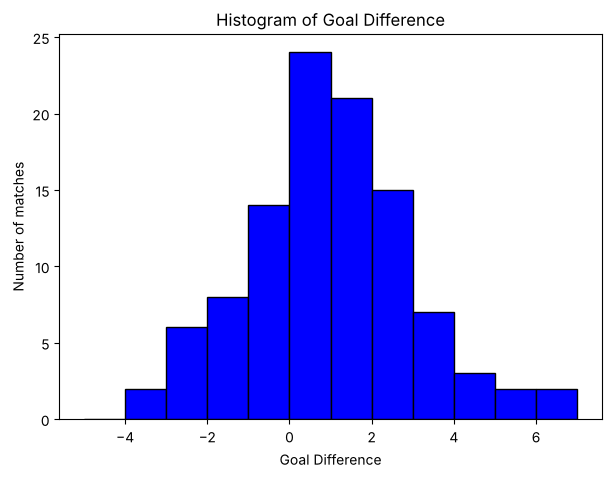

In [10]:
# Plotting a histogram of goal difference
plt.figure(figsize=(7,5))
plt.hist(df["Goal_Diff"], bins=range(-5, 8), edgecolor="black", color="blue")
plt.xlabel("Goal Difference")
plt.ylabel("Number of matches")
plt.title("Histogram of Goal Difference")
plt.show()

In [11]:
# Checking for outliers using the IQR method
pct25 = np.percentile(df["Goal_Diff"], 25)
pct75 = np.percentile(df["Goal_Diff"], 75)
iqr = pct75 - pct25
lower = pct25 - 1.5 * iqr
upper = pct75 + 1.5 * iqr
outliers = df[(df["Goal_Diff"] < lower) | (df["Goal_Diff"] > upper)]

print("IQR: %.2f (25th percentile: %.2f, 75th percentile: %.2f)" % (iqr, pct25, pct75))
print("Outlier boundaries: below %.2f or above %.2f" % (lower, upper))
print("Number of outliers: %d" % len(outliers))
print("Outlier values:", list(outliers["Goal_Diff"]))

# outliers are real match results, so all rows are kept

IQR: 3.00 (25th percentile: -1.00, 75th percentile: 2.00)
Outlier boundaries: below -5.50 or above 6.50
Number of outliers: 0
Outlier values: []


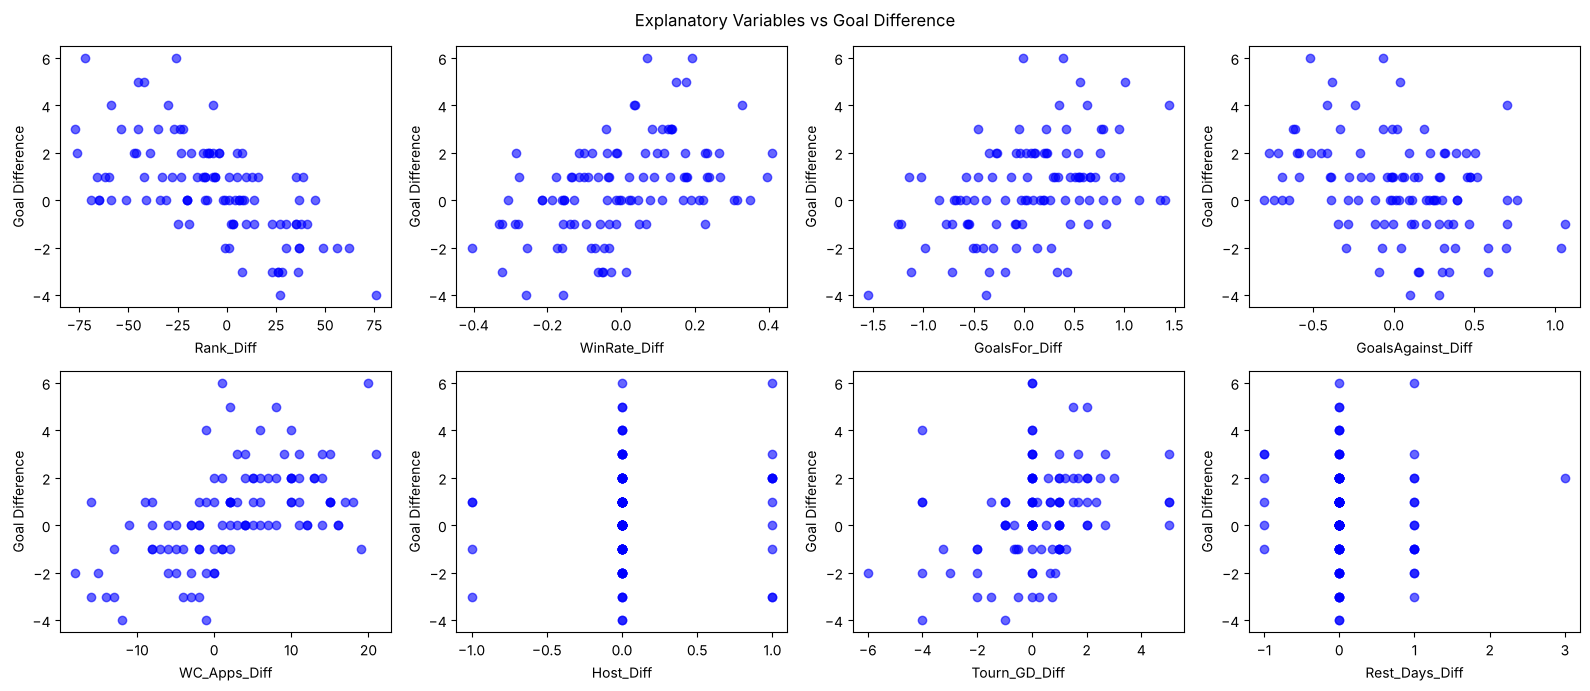

Correlation with Goal_Diff:
Rank_Diff           -0.62
WinRate_Diff         0.45
GoalsFor_Diff        0.42
GoalsAgainst_Diff   -0.34
WC_Apps_Diff         0.54
Host_Diff            0.12
Tourn_GD_Diff        0.32
Rest_Days_Diff      -0.03
Name: Goal_Diff, dtype: float64


In [12]:
# Plotting each explanatory variable against Goal_Diff to check linearity
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,7))
for ax, col in zip(axes.flatten(), df.columns[:-1]):
    ax.scatter(df[col], df["Goal_Diff"], color="blue", alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("Goal Difference")
fig.suptitle("Explanatory Variables vs Goal Difference")
fig.tight_layout()
plt.savefig("figures/2_1_scatterplots.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculating the correlation of each variable with Goal_Diff
print("Correlation with Goal_Diff:")
print(df.corr()["Goal_Diff"].drop("Goal_Diff").round(2))

# Building the linear regression model

Same as the practicals, we split the data into 60% training and 40% test sets.

In [13]:
# Separate explanatory variables (x) from the response variable (y)
x = df.iloc[:,:-1].values
y = df.iloc[:,-1].values

# Split dataset into 60% training and 40% test sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.4, random_state=0)

# Build a linear regression model
model = LinearRegression()

# Train (fit) the linear regression model using the training set
model.fit(X_train, y_train)

# Print the intercept and coefficients
print("Intercept: %.4f" % model.intercept_)
for name, coef in zip(df.columns[:-1], model.coef_):
    print("%s: %.4f" % (name, coef))

# Writing the full regression equation
equation = "Goal_Diff = %.4f" % model.intercept_
for name, coef in zip(df.columns[:-1], model.coef_):
    if coef >= 0:
        equation = equation + " + %.4f (%s)" % (coef, name)
    else:
        equation = equation + " - %.4f (%s)" % (abs(coef), name)
print("\n" + equation)

Intercept: 0.1784
Rank_Diff: -0.0242
WinRate_Diff: 1.1340
GoalsFor_Diff: 0.6753
GoalsAgainst_Diff: 0.3696
WC_Apps_Diff: 0.0406
Host_Diff: 0.0632
Tourn_GD_Diff: -0.0412
Rest_Days_Diff: -0.5842

Goal_Diff = 0.1784 - 0.0242 (Rank_Diff) + 1.1340 (WinRate_Diff) + 0.6753 (GoalsFor_Diff) + 0.3696 (GoalsAgainst_Diff) + 0.0406 (WC_Apps_Diff) + 0.0632 (Host_Diff) - 0.0412 (Tourn_GD_Diff) - 0.5842 (Rest_Days_Diff)


In [14]:
# Predicting the values of (y) in the test set
y_pred = model.predict(X_test)

# Showing the predicted values next to the actual values
df_pred = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(df_pred.head(10).round(2))

# Mean Absolute Error
mae = metrics.mean_absolute_error(y_test, y_pred)
# Mean Squared Error
mse = metrics.mean_squared_error(y_test, y_pred)
# Root Mean Square Error
rmse = math.sqrt(mse)
# Normalised Root Mean Square Error
y_max = y.max()
y_min = y.min()
rmse_norm = rmse / (y_max - y_min)
# R-Squared
r_2 = metrics.r2_score(y_test, y_pred)

print("\nLinear regression performance:")
print("MAE: %.3f" % mae)
print("MSE: %.3f" % mse)
print("RMSE: %.3f" % rmse)
print("RMSE (Normalised): %.3f" % rmse_norm)
print("R^2: %.3f" % r_2)

   Actual  Predicted
0       6       0.21
1       5       1.62
2       0       1.20
3      -1      -1.39
4       0      -0.04
5       1       1.20
6       2       1.22
7       2       1.19
8      -2      -1.52
9       0       2.97

Linear regression performance:
MAE: 1.569
MSE: 3.968
RMSE: 1.992
RMSE (Normalised): 0.199
R^2: 0.040


# Comparing with a baseline model

The baseline model predicts the mean of the training set every time.

In [15]:
# Calculating the mean of (y) in the training set
y_base = np.mean(y_train)

# Using the mean as the prediction for every row in the test set
y_pred_base = [y_base] * len(y_test)

# Calculating the performance of the baseline model
mae_base = metrics.mean_absolute_error(y_test, y_pred_base)
mse_base = metrics.mean_squared_error(y_test, y_pred_base)
rmse_base = math.sqrt(mse_base)
rmse_norm_base = rmse_base / (y_max - y_min)
r_2_base = metrics.r2_score(y_test, y_pred_base)

# Displaying both models side by side
df_compare = pd.DataFrame({
    "Linear regression": [mae, mse, rmse, rmse_norm, r_2],
    "Baseline": [mae_base, mse_base, rmse_base, rmse_norm_base, r_2_base]},
    index=["MAE", "MSE", "RMSE", "NRMSE", "R^2"])
df_compare.round(3)

,Linear regression,Baseline
MAE,1.569,1.558
MSE,3.968,4.356
RMSE,1.992,2.087
NRMSE,0.199,0.209
R^2,0.040,-0.054


# Building the model with statsmodels

statsmodels gives the p-value of each explanatory variable and the adjusted R². Same as the practicals, it is built on all the rows.

In [16]:
# Separate explanatory variables (x) from the response variable (y)
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

# Build and evaluate the linear regression model
x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
pred = model.predict(x)
model_details = model.summary()
print(model_details)

                            OLS Regression Results                            
Dep. Variable:              Goal_Diff   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.388
Method:                 Least Squares   F-statistic:                     9.153
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           2.95e-09
Time:                        16:06:48   Log-Likelihood:                -190.68
No. Observations:                 104   AIC:                             399.4
Df Residuals:                      95   BIC:                             423.2
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.1282      0.16

# Evaluating each version of the model

We are trying the four optimisation tips from Week 9. Every version is evaluated in the same way, so we put the steps into a function.

In [17]:
# list for storing the results of each version
results = []

def evaluate_model(x_df, y, model_name):
    # same 60/40 split as before
    X_train, X_test, y_train, y_test = train_test_split(x_df.values, y.values, test_size=0.4, random_state=0)

    # building the sklearn model and predicting the test set
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # performance on the test set
    mae = metrics.mean_absolute_error(y_test, y_pred)
    rmse = math.sqrt(metrics.mean_squared_error(y_test, y_pred))
    rmse_norm = rmse / (y.max() - y.min())
    r_2 = metrics.r2_score(y_test, y_pred)

    # statsmodels model on all the rows for the adjusted R^2
    ols = sm.OLS(y, sm.add_constant(x_df)).fit()

    results.append({"Model": model_name, "Variables": x_df.shape[1],
                    "MAE": mae, "RMSE": rmse, "NRMSE": rmse_norm, "R^2 (test)": r_2,
                    "R^2 (statsmodels)": ols.rsquared, "Adj. R^2 (statsmodels)": ols.rsquared_adj})

    print(model_name)
    print("\t MAE: %.3f  RMSE: %.3f  NRMSE: %.3f  R^2: %.3f" % (mae, rmse, rmse_norm, r_2))
    print("\t Adjusted R^2 (statsmodels): %.3f" % ols.rsquared_adj)
    return ols

# Separate explanatory variables (x) from the response variable (y)
x_original = df.iloc[:,:-1]
y_all = df.iloc[:,-1]

# Evaluating the original model
ols_original = evaluate_model(x_original, y_all, "Original model")

Original model
	 MAE: 1.569  RMSE: 1.992  NRMSE: 0.199  R^2: 0.040
	 Adjusted R^2 (statsmodels): 0.388


# Optimisation tip 1: Log transformation

A gap of 10 places in the FIFA ranking means more at the top (1st vs 11th) than near the bottom (70th vs 80th), so we apply a log transformation to Rank_Diff. Rank_Diff has negative values, so we use a signed log: sign(Rank_Diff) × log(1 + |Rank_Diff|).

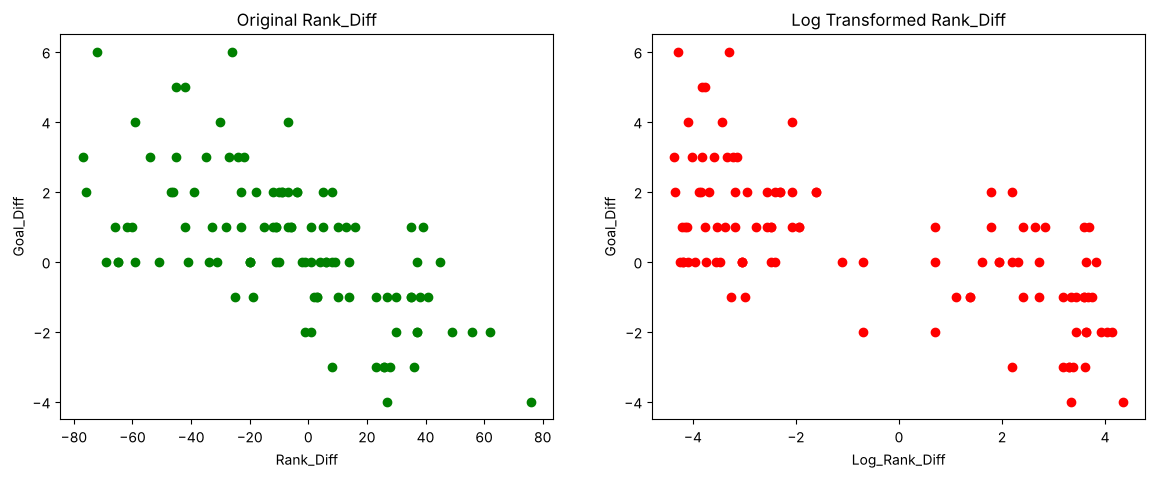

Correlation of Rank_Diff with Goal_Diff: -0.621
Correlation of Log_Rank_Diff with Goal_Diff: -0.653


In [18]:
# Applying the signed log transformation to Rank_Diff
df_log = df.copy()
df_log["Log_Rank_Diff"] = np.sign(df_log["Rank_Diff"]) * np.log(1 + np.abs(df_log["Rank_Diff"]))

# Visualise the effect of the transformation
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.scatter(df_log["Rank_Diff"], df_log["Goal_Diff"], color="green")
plt.title("Original Rank_Diff")
plt.xlabel("Rank_Diff")
plt.ylabel("Goal_Diff")

plt.subplot(1,2,2)
plt.scatter(df_log["Log_Rank_Diff"], df_log["Goal_Diff"], color="red")
plt.title("Log Transformed Rank_Diff")
plt.xlabel("Log_Rank_Diff")
plt.ylabel("Goal_Diff")

plt.show()

print("Correlation of Rank_Diff with Goal_Diff: %.3f" % df_log["Rank_Diff"].corr(df_log["Goal_Diff"]))
print("Correlation of Log_Rank_Diff with Goal_Diff: %.3f" % df_log["Log_Rank_Diff"].corr(df_log["Goal_Diff"]))

In [19]:
# Drop the original Rank_Diff variable
df_log = df_log.drop("Rank_Diff", axis=1)

# Rearrange the variables so that Goal_Diff is the last column
df_log = df_log[["Log_Rank_Diff", "WinRate_Diff", "GoalsFor_Diff", "GoalsAgainst_Diff",
                 "WC_Apps_Diff", "Host_Diff", "Tourn_GD_Diff", "Rest_Days_Diff", "Goal_Diff"]]

x_log = df_log.iloc[:,:-1]
ols_log = evaluate_model(x_log, y_all, "Tip 1: log transformation of Rank_Diff")

Tip 1: log transformation of Rank_Diff
	 MAE: 1.537  RMSE: 1.928  NRMSE: 0.193  R^2: 0.100
	 Adjusted R^2 (statsmodels): 0.405


# Optimisation tip 2: Removing collinearity

We are checking for pairs of explanatory variables that are strongly correlated (|r| of 0.7 or more).

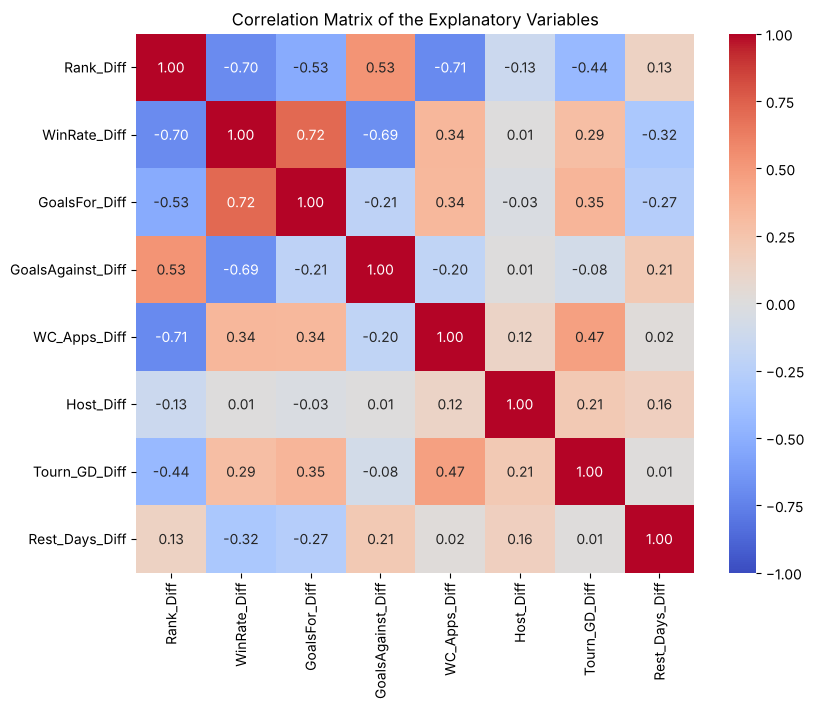

Strongly correlated pairs:
	 Rank_Diff and WC_Apps_Diff: r = -0.710
	 WinRate_Diff and GoalsFor_Diff: r = 0.719


In [20]:
# Correlation matrix of the explanatory variables
corr = df.iloc[:,:-1].corr()

# Plotting the correlation matrix as a heatmap
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of the Explanatory Variables")
plt.savefig("figures/2_1_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Printing the pairs with |r| >= 0.7
print("Strongly correlated pairs:")
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i,j]) >= 0.7:
            print("\t %s and %s: r = %.3f" % (corr.columns[i], corr.columns[j], corr.iloc[i,j]))

In [21]:
# WinRate_Diff and GoalsFor_Diff are the most correlated pair, and WinRate_Diff is also
# correlated with Rank_Diff (-0.70) and GoalsAgainst_Diff (-0.69), so we remove WinRate_Diff
x_collinear = df.drop(["WinRate_Diff", "Goal_Diff"], axis=1)
ols_collinear = evaluate_model(x_collinear, y_all, "Tip 2: WinRate_Diff removed")

Tip 2: WinRate_Diff removed
	 MAE: 1.552  RMSE: 1.959  NRMSE: 0.196  R^2: 0.072
	 Adjusted R^2 (statsmodels): 0.390


# Optimisation tip 3: Rescaling with z-score standardisation

After standardisation all variables are on the same scale, so the coefficients can be compared to see which variables matter most.

Tip 3: z-score standardisation
	 MAE: 1.569  RMSE: 1.992  NRMSE: 0.199  R^2: 0.040
	 Adjusted R^2 (statsmodels): 0.388

Standardised coefficients:
Tourn_GD_Diff       -0.016
Host_Diff            0.107
Rest_Days_Diff       0.113
WinRate_Diff        -0.311
GoalsAgainst_Diff   -0.344
WC_Apps_Diff         0.442
GoalsFor_Diff        0.503
Rank_Diff           -0.718
dtype: float64


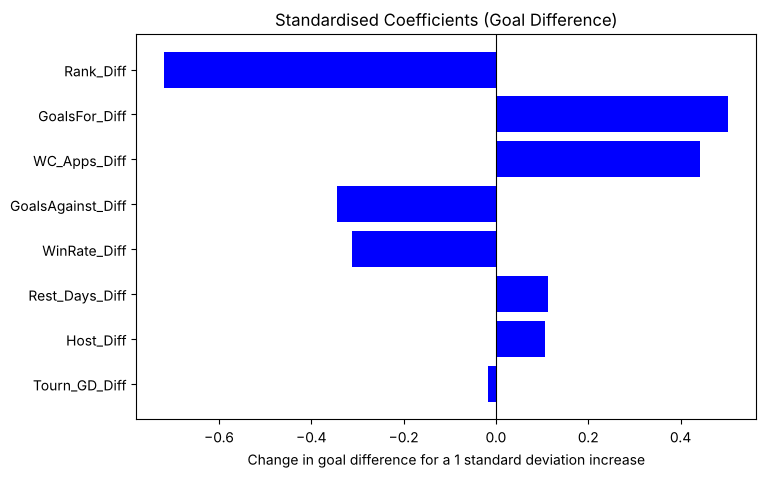

In [22]:
# Apply z-score standardisation to all explanatory variables
scaler = StandardScaler()
std_x = scaler.fit_transform(x_original.values)

# Restore the column names
std_x_df = pd.DataFrame(std_x, index=x_original.index, columns=x_original.columns)

ols_std = evaluate_model(std_x_df, y_all, "Tip 3: z-score standardisation")

# Standardised coefficients sorted by size
std_coef = ols_std.params.drop("const")
std_coef = std_coef.reindex(std_coef.abs().sort_values().index)
print("\nStandardised coefficients:")
print(std_coef.round(3))

# Plotting the standardised coefficients
plt.figure(figsize=(8,5))
plt.barh(std_coef.index, std_coef.values, color="blue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in goal difference for a 1 standard deviation increase")
plt.title("Standardised Coefficients (Goal Difference)")
plt.savefig("figures/2_1_standardised_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

# Optimisation tip 4: Gaussian transformation (Yeo-Johnson)

In [23]:
# Create a Yeo-Johnson transformer
transformer = PowerTransformer()

# Apply the transformer to make all explanatory variables more Gaussian-looking
gauss_x = transformer.fit_transform(x_original.values)

# Restore the column names
gauss_x_df = pd.DataFrame(gauss_x, index=x_original.index, columns=x_original.columns)

ols_gauss = evaluate_model(gauss_x_df, y_all, "Tip 4: Yeo-Johnson transformation")

Tip 4: Yeo-Johnson transformation
	 MAE: 1.578  RMSE: 2.006  NRMSE: 0.201  R^2: 0.026
	 Adjusted R^2 (statsmodels): 0.385


# Comparing all versions of the model

In [24]:
df_results = pd.DataFrame(results)
df_results.round(3)

,Model,Variables,MAE,RMSE,NRMSE,R^2 (test),R^2 (statsmodels),Adj. R^2 (statsmodels)
0,Original model,8,1.569,1.992,0.199,0.040,0.435,0.388
1,Tip 1: log transformation of Rank_Diff,8,1.537,1.928,0.193,0.100,0.451,0.405
2,Tip 2: WinRate_Diff removed,7,1.552,1.959,0.196,0.072,0.431,0.390
3,Tip 3: z-score standardisation,8,1.569,1.992,0.199,0.040,0.435,0.388
4,Tip 4: Yeo-Johnson transformation,8,1.578,2.006,0.201,0.026,0.432,0.385


# Final model

Tip 1 and Tip 2 both improved the model, so the final model uses both. The dataset has 8 explanatory variables, but the final model uses 7 because WinRate_Diff was removed in Tip 2.

In [25]:
# Final model: log transformed Rank_Diff and WinRate_Diff removed
x_final = df_log.drop(["WinRate_Diff", "Goal_Diff"], axis=1)
print("Variables in the final model:", list(x_final.columns))

ols_final = evaluate_model(x_final, y_all, "Final model (Tip 1 + Tip 2)")

Variables in the final model: ['Log_Rank_Diff', 'GoalsFor_Diff', 'GoalsAgainst_Diff', 'WC_Apps_Diff', 'Host_Diff', 'Tourn_GD_Diff', 'Rest_Days_Diff']
Final model (Tip 1 + Tip 2)
	 MAE: 1.498  RMSE: 1.861  NRMSE: 0.186  R^2: 0.162
	 Adjusted R^2 (statsmodels): 0.407


Goal_Diff = 0.2287 - 0.2628 (Log_Rank_Diff) + 0.7463 (GoalsFor_Diff) - 0.0625 (GoalsAgainst_Diff) + 0.0343 (WC_Apps_Diff) - 0.0076 (Host_Diff) - 0.0062 (Tourn_GD_Diff) - 0.5609 (Rest_Days_Diff)


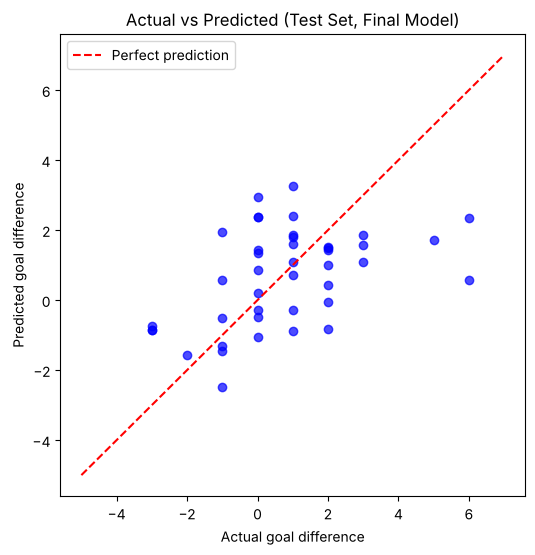

In [26]:
# Training the final model with sklearn to get the regression equation
X_train, X_test, y_train, y_test = train_test_split(x_final.values, y_all.values, test_size=0.4, random_state=0)
final_model = LinearRegression()
final_model.fit(X_train, y_train)
y_pred_final = final_model.predict(X_test)

equation = "Goal_Diff = %.4f" % final_model.intercept_
for name, coef in zip(x_final.columns, final_model.coef_):
    if coef >= 0:
        equation = equation + " + %.4f (%s)" % (coef, name)
    else:
        equation = equation + " - %.4f (%s)" % (abs(coef), name)
print(equation)

# Plotting the actual values against the predicted values
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_final, color="blue", alpha=0.7)
plt.plot([-5, 7], [-5, 7], color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual goal difference")
plt.ylabel("Predicted goal difference")
plt.title("Actual vs Predicted (Test Set, Final Model)")
plt.legend()
plt.savefig("figures/2_1_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# statsmodels summary of the final model
print(ols_final.summary())

                            OLS Regression Results                            
Dep. Variable:              Goal_Diff   R-squared:                       0.447
Model:                            OLS   Adj. R-squared:                  0.407
Method:                 Least Squares   F-statistic:                     11.09
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           3.33e-10
Time:                        16:06:50   Log-Likelihood:                -189.59
No. Observations:                 104   AIC:                             395.2
Df Residuals:                      96   BIC:                             416.3
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.1889      0.16

# Repeated random splits

The test set only has 42 matches, so the results can change a lot depending on which matches are in it. We are repeating the 60/40 split 100 times and taking the average.

In [28]:
def repeated_split(x_df, y, repeats=100):
    r2_model = []
    rmse_model = []
    r2_base = []
    rmse_base = []
    for i in range(repeats):
        # a different split each time
        X_train, X_test, y_train, y_test = train_test_split(x_df.values, y.values, test_size=0.4, random_state=i)

        # linear regression model
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        r2_model.append(metrics.r2_score(y_test, y_pred))
        rmse_model.append(math.sqrt(metrics.mean_squared_error(y_test, y_pred)))

        # baseline model
        y_pred_base = [np.mean(y_train)] * len(y_test)
        r2_base.append(metrics.r2_score(y_test, y_pred_base))
        rmse_base.append(math.sqrt(metrics.mean_squared_error(y_test, y_pred_base)))
    return np.mean(r2_model), np.mean(rmse_model), np.mean(r2_base), np.mean(rmse_base)

r2_o, rmse_o, r2_b, rmse_b = repeated_split(x_original, y_all)
r2_f, rmse_f, r2_b, rmse_b = repeated_split(x_final, y_all)

print("Average over 100 random 60/40 splits:")
print("\t Original model -> R^2: %.3f  RMSE: %.3f" % (r2_o, rmse_o))
print("\t Final model    -> R^2: %.3f  RMSE: %.3f" % (r2_f, rmse_f))
print("\t Baseline       -> R^2: %.3f  RMSE: %.3f" % (r2_b, rmse_b))

Average over 100 random 60/40 splits:
	 Original model -> R^2: 0.233  RMSE: 1.704
	 Final model    -> R^2: 0.275  RMSE: 1.657
	 Baseline       -> R^2: -0.047  RMSE: 2.006
